In [1]:
import os
import sys

# Run from the project root so `src` imports and relative data paths resolve.
if os.path.basename(os.getcwd()) == "jupyter_notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
import glob
import os

import numpy as np
import torch
import matplotlib.pyplot as plt

from train_kinematic_hardening import AdjointVariationalODE
from src.utilities import apply_plot_style

apply_plot_style()

In [3]:
# Run to visualize: None picks the newest run folder with a saved checkpoint.
RUN_DIR = "runs/20261018-201843"
CHECKPOINT_NAME = "interrupted.ckpt"  # or "best-epoch=N.ckpt", "interrupted.ckpt"

if RUN_DIR is None:
    candidates = sorted(glob.glob(os.path.join("runs", "*", "checkpoints", CHECKPOINT_NAME)))
    if not candidates:
        raise FileNotFoundError(f"No run in runs/ has checkpoints/{CHECKPOINT_NAME} yet.")
    checkpoint_path = candidates[-1]
    RUN_DIR = os.path.dirname(os.path.dirname(checkpoint_path))
else:
    checkpoint_path = os.path.join(RUN_DIR, "checkpoints", CHECKPOINT_NAME)

# The model type (potential or invertible) and hidden size come from the checkpoint.
model = AdjointVariationalODE.load_from_checkpoint(checkpoint_path, map_location="cpu")
model.eval()
print(f"Run:   {RUN_DIR}")
print(f"Model: {model.hparams.model} ({type(model.solver).__name__}), hidden size {model.hparams.hidden_size}")

Run:   runs/20261018-201843
Model: potential (VariationalODESolver), hidden size 64


In [4]:
# The dataset the model was trained on, recorded in the checkpoint.
dataset_path = model.hparams.get("dataset_path") or "datasets/kinematic_hardening_dataset.pt"
dataset = torch.load(dataset_path, weights_only=False)
metadata = dataset["metadata"]
times = dataset["times"].numpy()
dt = metadata["ou"]["dt"]
if not np.isclose(model.hparams.dt, dt):
    raise ValueError(f"Model was trained with dt={model.hparams.dt}, dataset has dt={dt}.")

# strain, plastic_strain and stress per split, as numpy arrays of shape (trajectories, time).
splits = {
    name: {key: value.numpy() for key, value in dataset[name].items()}
    for name in ("train", "validation", "test")
}
test_programs = metadata["test"]["programs"]

print(f"Dataset: {dataset_path}")
for name, split in splits.items():
    print(f"  {name:<10} strain {split['strain'].shape}")
print(f"  time grid: T = {times[-1]:g}, dt = {dt:g}")

Dataset: /Users/mraj/Documents/Research/Data_Sampling/datasets/kinematic_hardening_dataset.pt
  train      strain (64, 12001)
  validation strain (16, 12001)
  test       strain (30, 12001)
  time grid: T = 1, dt = 8.33333e-05


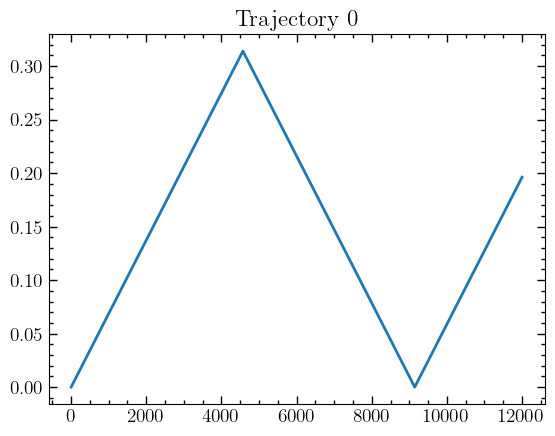

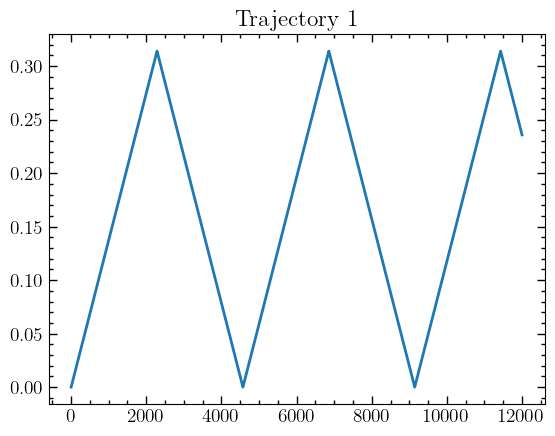

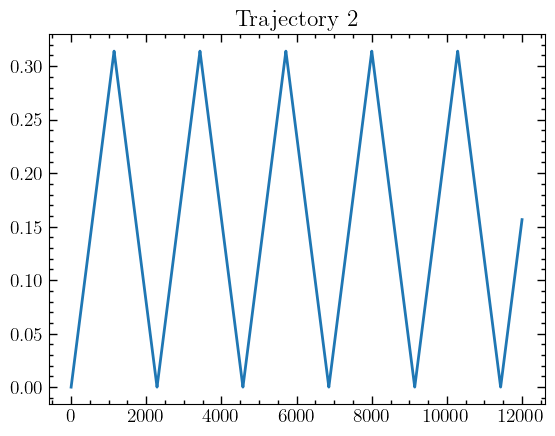

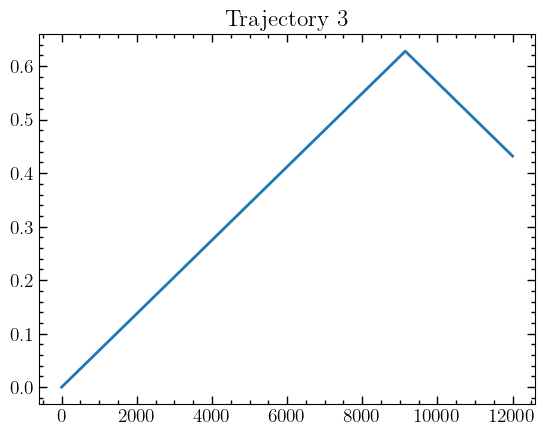

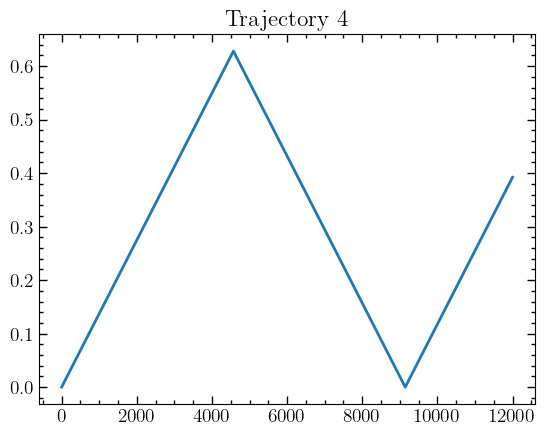

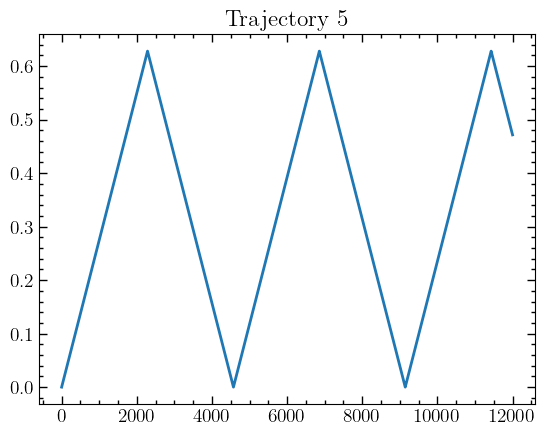

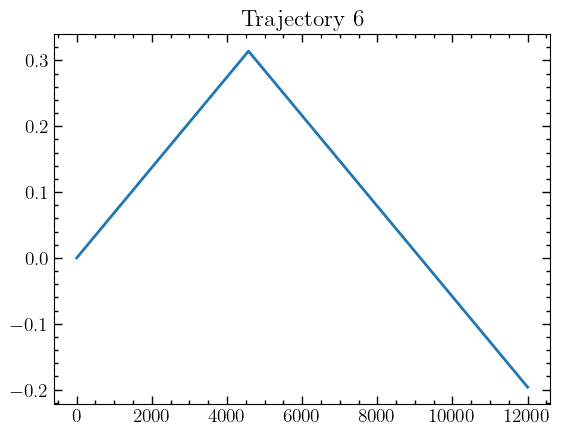

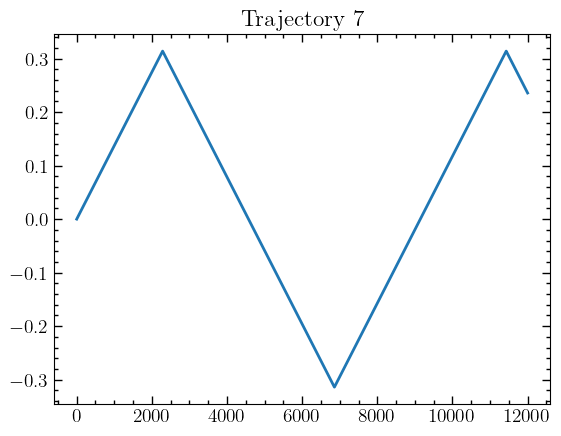

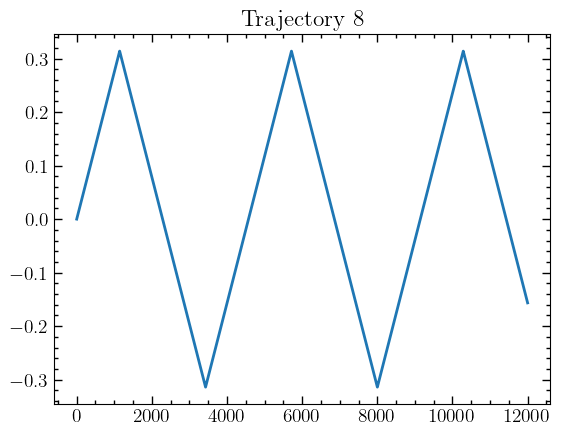

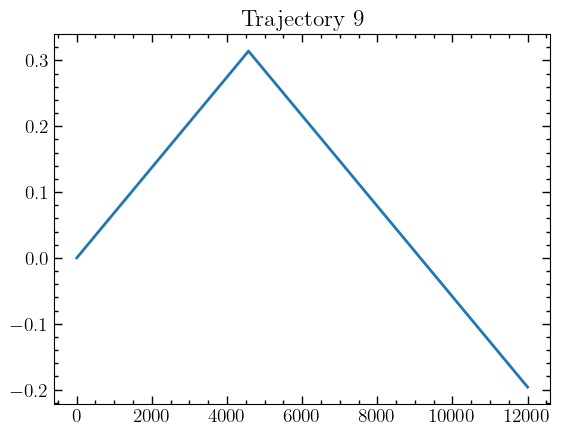

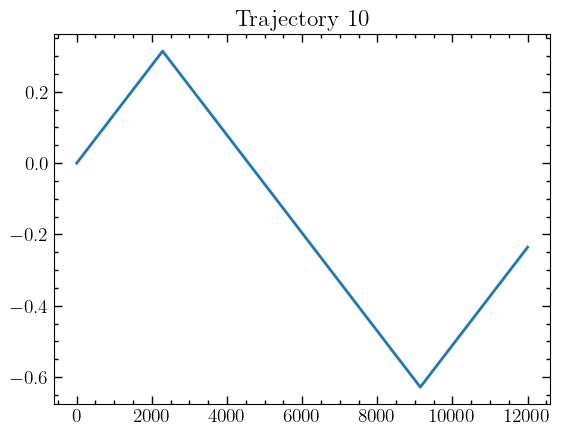

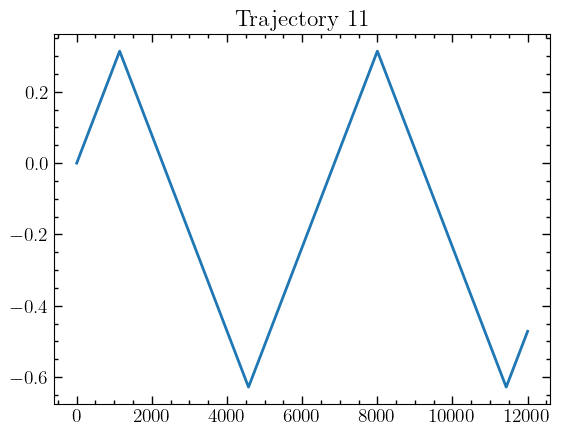

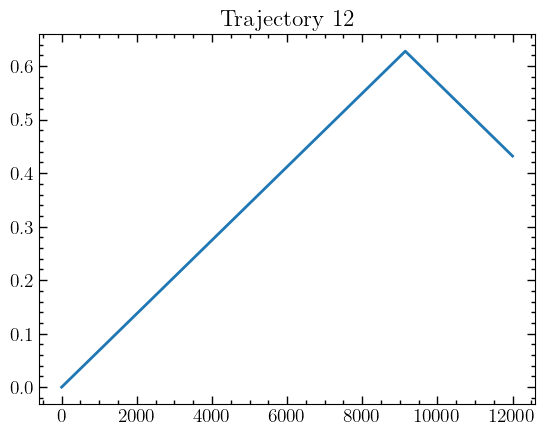

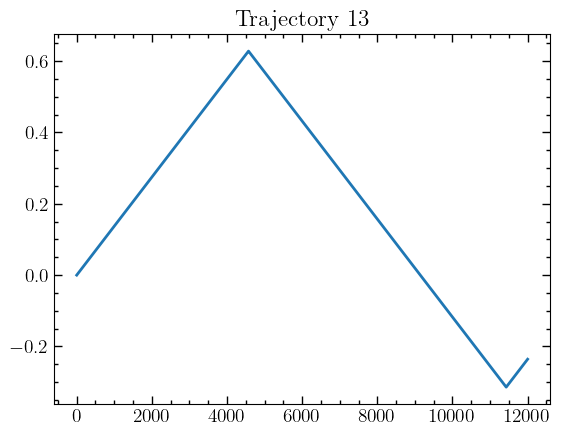

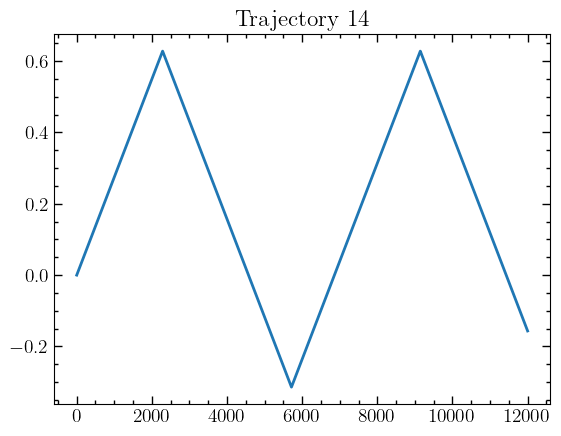

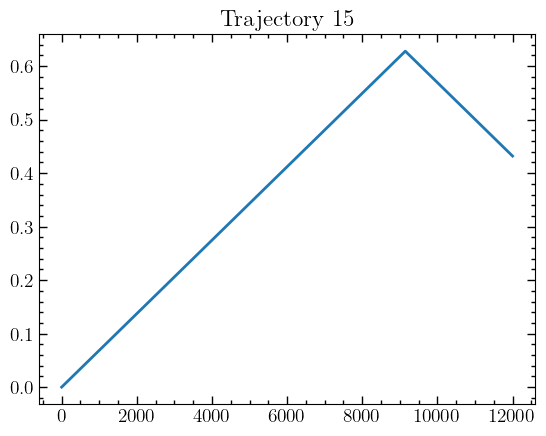

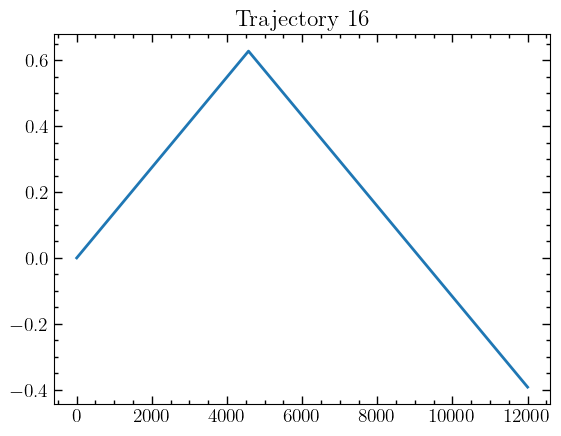

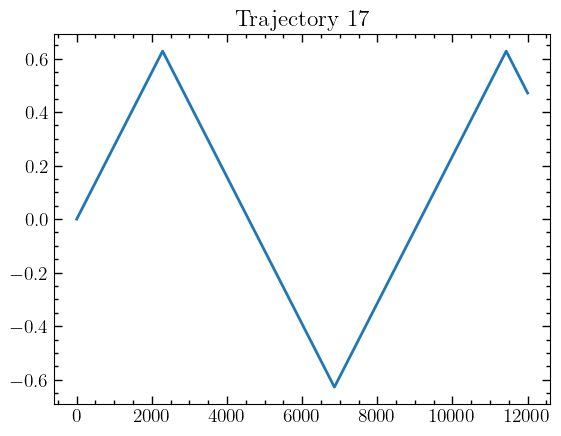

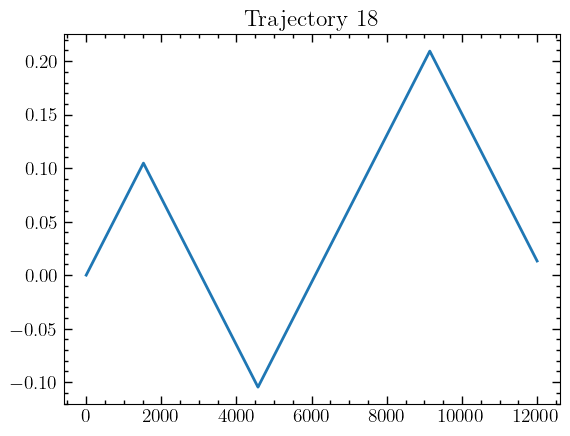

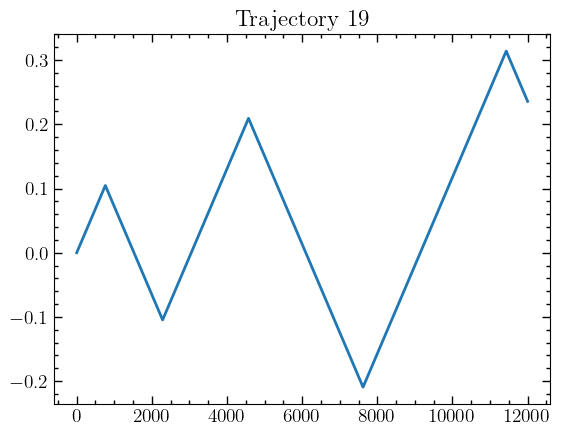

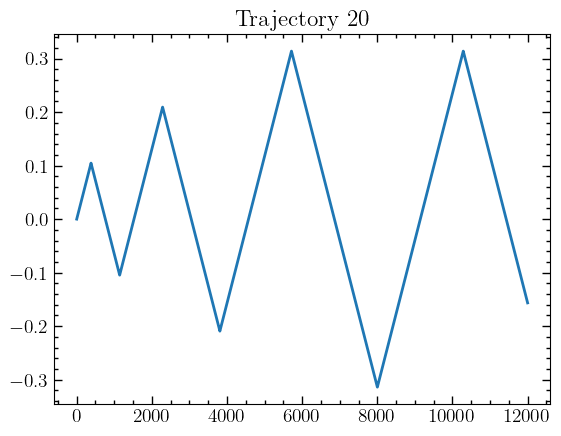

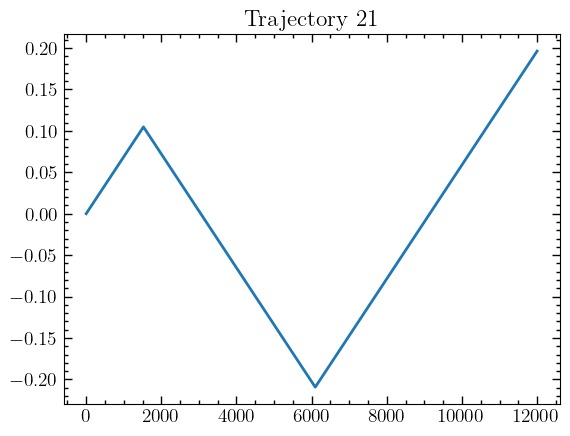

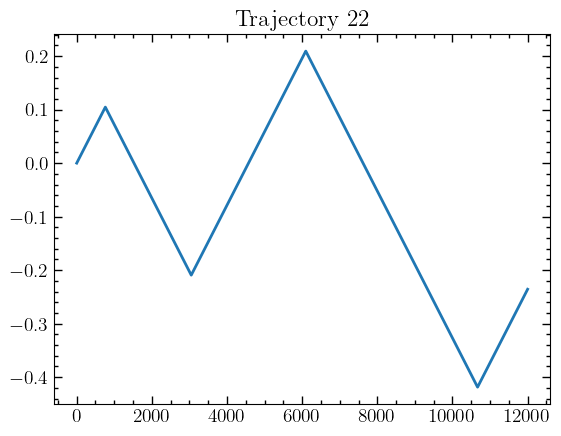

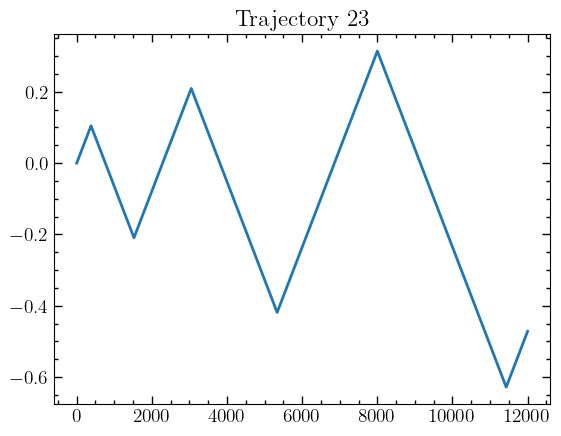

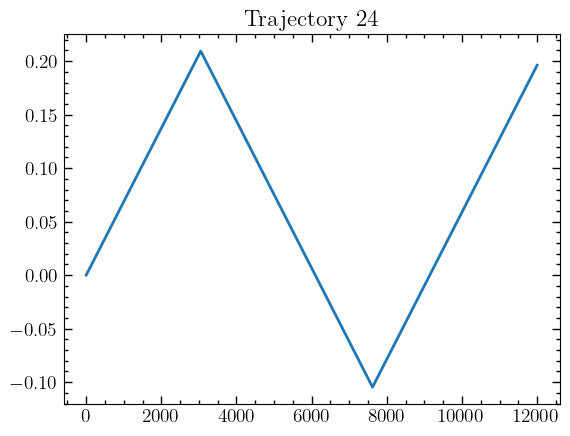

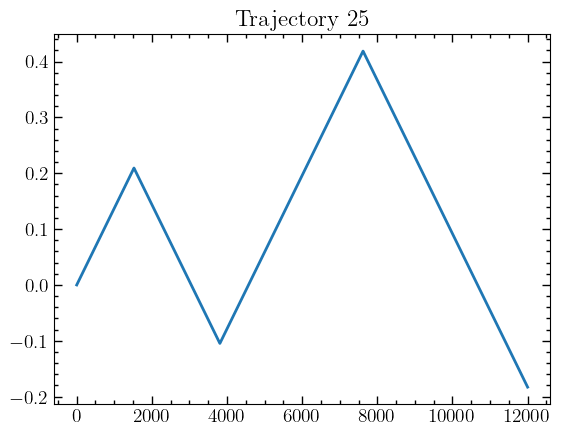

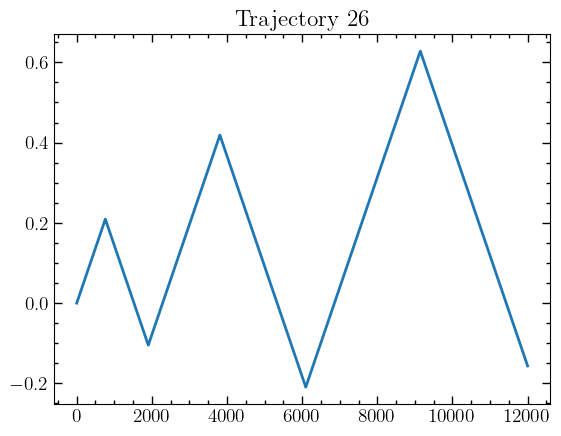

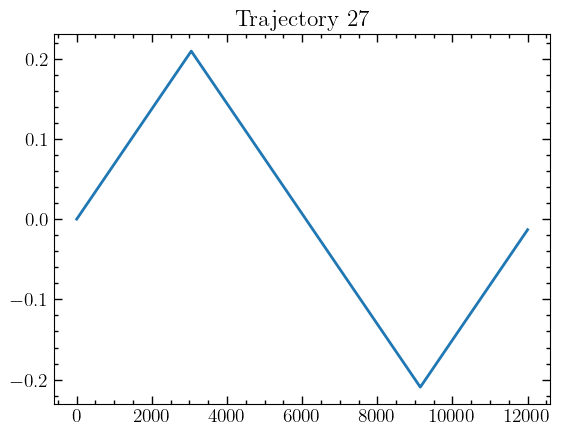

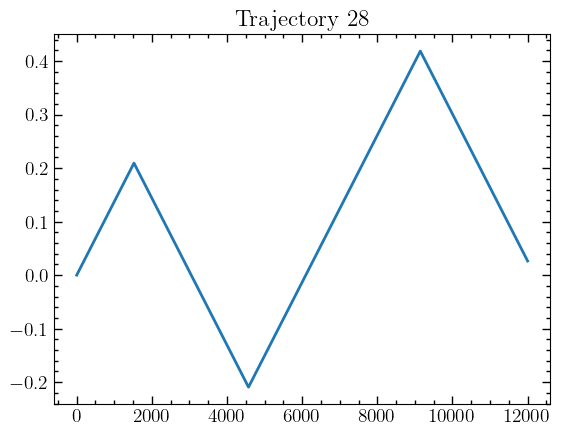

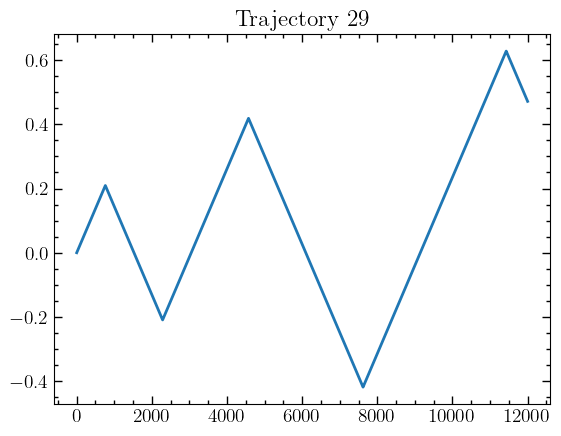

In [5]:
for i in range(splits['test']['strain'].shape[0]):
    plt.plot(splits['test']['strain'][i])
    plt.title(f"Trajectory {i}")
    plt.show()

In [20]:
splits['test']['strain'][i].shape

(12001,)